# Next-Day Stock Price Prediction

Forecasting the next trading day's closing price of a single NSE stock from the previous `WINDOWS` days of market data. Models predict the next-day return, which is converted back to a price and evaluated against rule-based baselines on a chronological hold-out set.

Set `SYMBOL`, `WINDOWS` and `TEST_PART` below, then run all cells.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
from pathlib import Path

SYMBOL = "TCS"
WINDOWS = 10
TEST_PART = 0.2
csv_path = "Stock_Price_Data.csv"

FIG_DIR = Path("reports/figures")          # figures used in the README
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Data Loading

The source file contains daily NSE data for ten stocks in long format. A single symbol is selected and only the regular `EQ` series is retained; `BL` (block-deal) rows are excluded, as they duplicate trading days.

In [11]:
def load_stock(csv_path, symbols):
    df = pd.read_csv(filepath_or_buffer=csv_path)
    df = df[(df["Series"] == "EQ") & (df["Symbol"] == symbols)].copy()
    if df.empty:
        raise ValueError(f"Symbol {symbols!r} not found in {csv_path}")
    df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%y")
    df = df.rename(columns={"No. of Trades": "Trades",
                            "Total Traded Quantity": "Volume",
                            "% Dly Qt to Traded Qty":"R_del_trd",
                            "Average Price": "Average",
                            "Open Price": "Open",
                            "Close Price": "Close",
                            "High Price": "High",
                            "Low Price": "Low"})
    df = df.sort_values("Date").set_index("Date")
    return df[["Prev Close", "Open", "High", "Low",
               "Close", "Average", "Volume", "Trades", "R_del_trd"]]

In [12]:
df = load_stock(csv_path=csv_path, symbols=SYMBOL)
print(len(df), df.index.min(), df.index.max())
print("Nan:", df.isna().sum().sum())
df.head()

496 2019-03-05 00:00:00 2021-03-03 00:00:00
Nan: 0


,Prev Close,Open,High,Low,Close,Average,Volume,Trades,R_del_trd
Date,,,,,,,,,
2019-03-05,1995.4,2005.0,2007.00,1976.60,1988.1,1987.11,2449622,151723,56.94
2019-03-06,1988.1,1989.3,2015.00,1985.05,1999.6,2001.30,2635047,179625,47.72
2019-03-07,1999.6,2005.0,2024.05,2000.20,2013.3,2014.40,2539884,126121,54.82
2019-03-08,2013.3,2025.0,2033.00,2010.05,2022.7,2023.03,2031071,116872,47.84
2019-03-11,2022.7,2028.9,2033.00,2003.65,2014.8,2017.10,3111689,104833,70.55


The output above reports the number of trading days, the date range and the count of missing values for the selected symbol. Missing values would need to be handled before feature engineering.

## 2. Exploratory Data Analysis

This section examines the magnitude of day-to-day price movements and the extent to which observable variables relate to the following day's return.

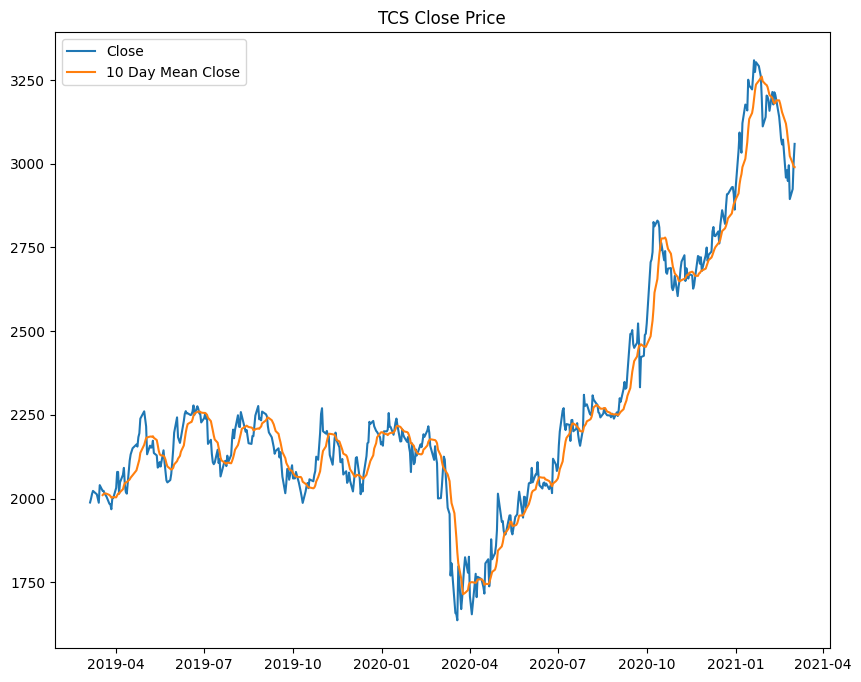

In [13]:
fig, ax = plt.subplots(figsize=(10,8))
ax.plot(df.index, df["Close"], label="Close")
ax.plot(df.index, df["Close"].rolling(WINDOWS).mean(), label=f"{WINDOWS} Day Mean Close")
ax.set_title(f"{SYMBOL} Close Price")
ax.legend()
fig.savefig(FIG_DIR / "eda_price.png", dpi=120, bbox_inches="tight")
plt.show()

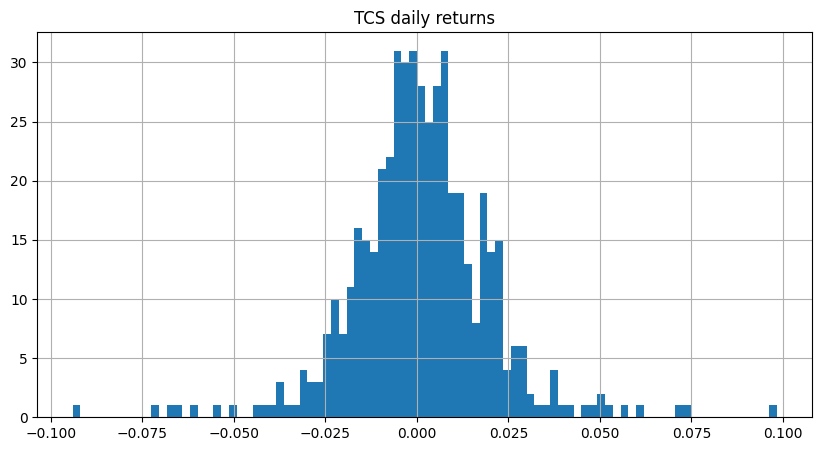

Std: 0.018924481466555978
mean: 0.0010496628649787334
Average Change: 0.013436112036684364
Minimum: 0.0
Maximum: 0.09845082042350373


In [14]:
pct = df["Close"].pct_change()
fig, ax = plt.subplots(figsize=(10, 5))
pct.hist(bins=90, ax=ax)
ax.set_title(f"{SYMBOL} daily returns")
fig.savefig(FIG_DIR / "eda_return_distribution.png", dpi=120, bbox_inches="tight")
plt.show()
print("Std:", pct.std())
print("mean:", pct.mean())
print("Average Change:", pct.abs().mean())
print("Minimum:", pct.abs().min())
print("Maximum:", pct.abs().max())

In [15]:
print("(Tomorrow Close = Today Close)[mean]:", df["Close"].diff().abs().mean())

(Tomorrow Close = Today Close)[mean]: 29.92303030303031


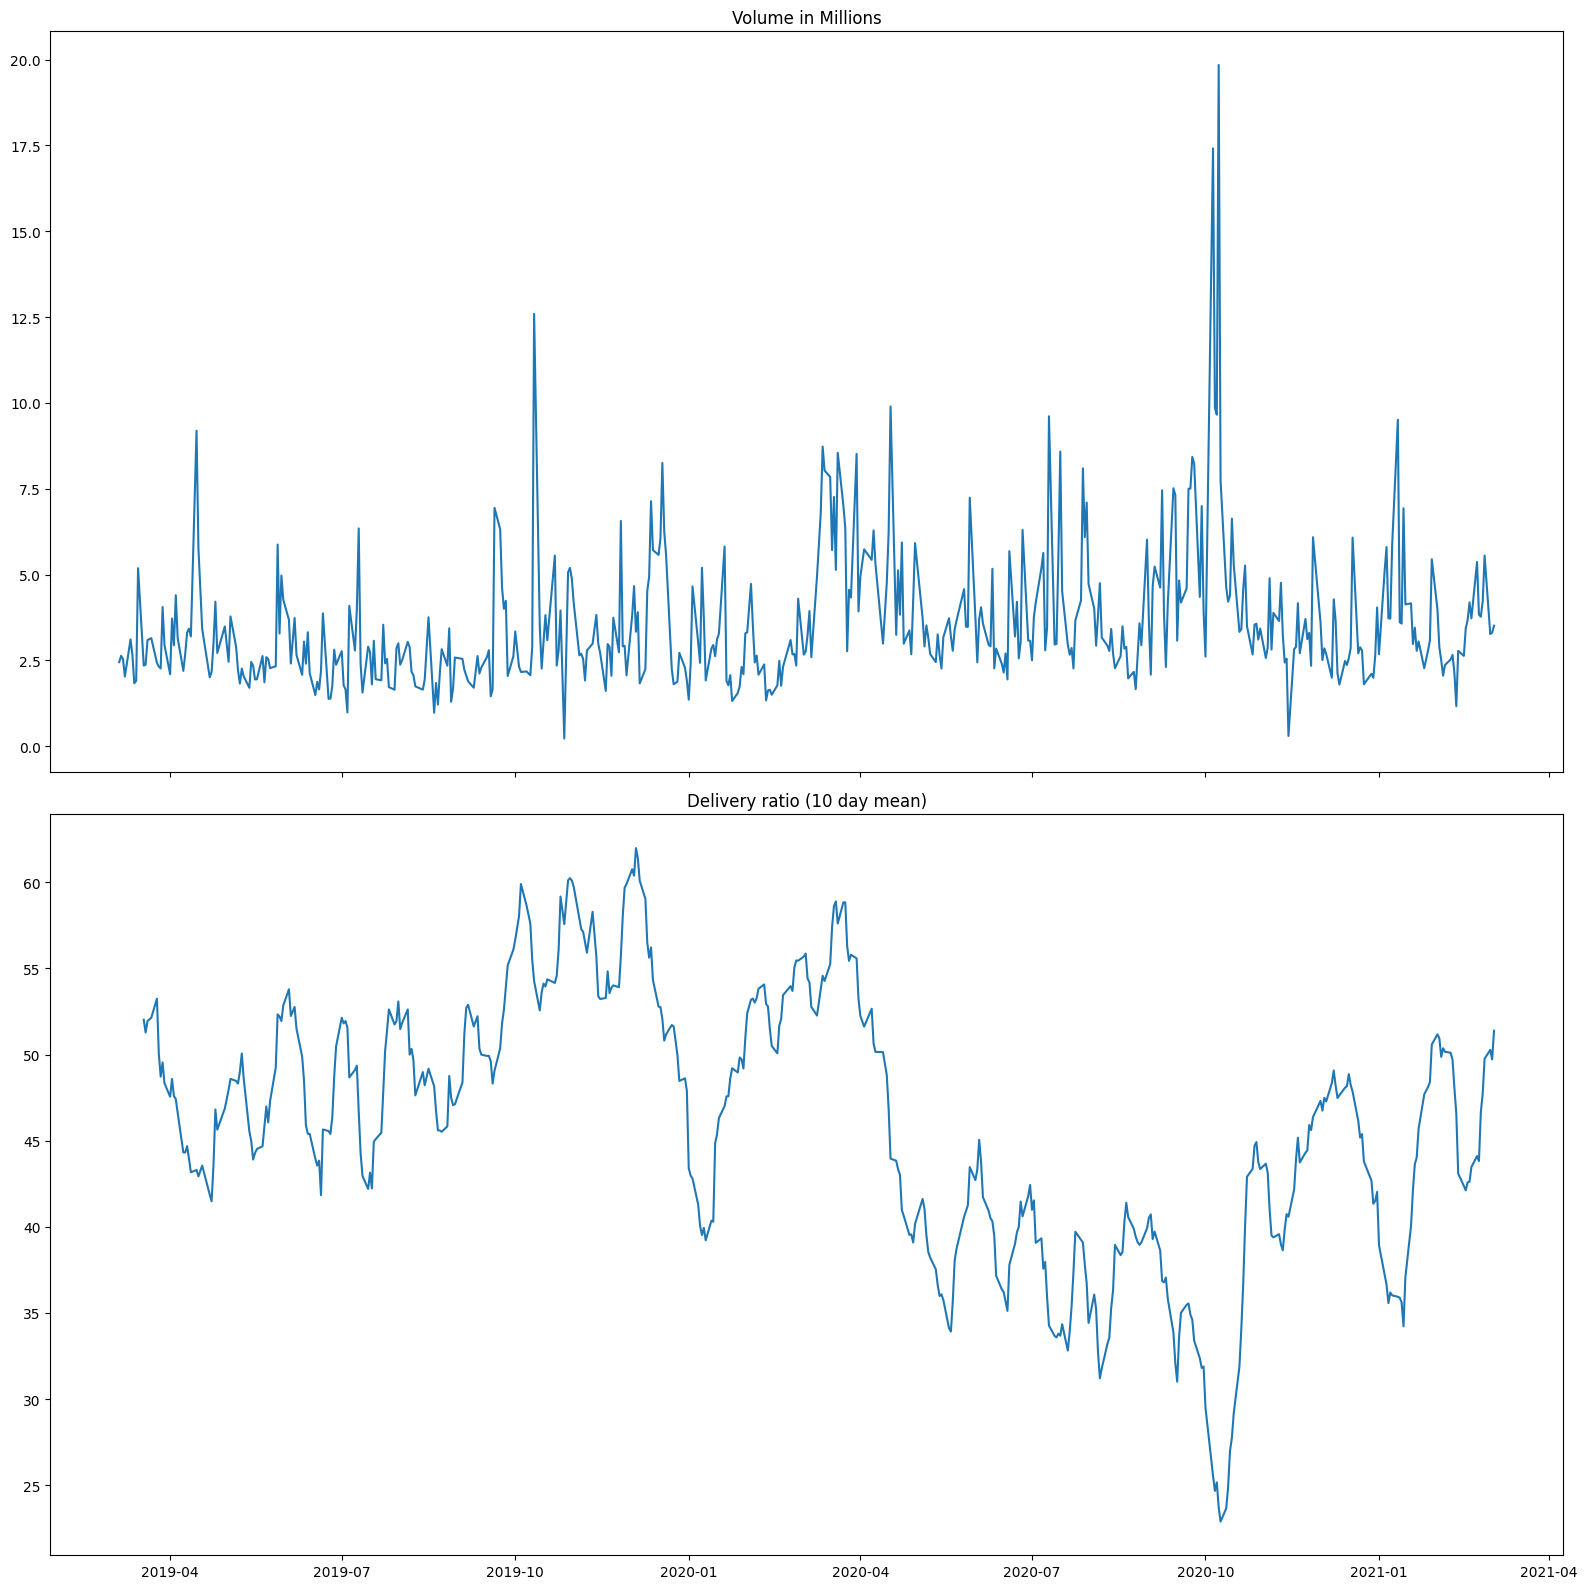

In [16]:
fig, ax = plt.subplots(2,1, figsize=(16,16), sharex=True)
ax[0].plot(df.index, df["Volume"] / 1e6)
ax[0].set_title("Volume in Millions")
ax[1].plot(df.index, df["R_del_trd"].rolling(WINDOWS).mean())
ax[1].set_title(f"Delivery ratio ({WINDOWS} day mean)")
plt.tight_layout()
plt.show()

Correlation of raw price levels — shown for reference; trending series correlate strongly regardless of predictive value.

In [17]:
df.corr()

,Prev Close,Open,High,Low,Close,Average,Volume,Trades,R_del_trd
Prev Close,1.000000,0.998327,0.996384,0.996016,0.993578,0.996055,0.007817,0.016650,-0.153544
Open,0.998327,1.000000,0.997282,0.997529,0.995072,0.997267,0.011950,0.019685,-0.161278
High,0.996384,0.997282,1.000000,0.996725,0.997896,0.999110,0.046669,0.054778,-0.176239
Low,0.996016,0.997529,0.996725,1.000000,0.997531,0.998759,-0.000769,0.000728,-0.172591
Close,0.993578,0.995072,0.997896,0.997531,1.000000,0.999120,0.026256,0.029641,-0.182139
Average,0.996055,0.997267,0.999110,0.998759,0.999120,1.000000,0.025553,0.029772,-0.177833
Volume,0.007817,0.011950,0.046669,-0.000769,0.026256,0.025553,1.000000,0.873331,-0.164091
Trades,0.016650,0.019685,0.054778,0.000728,0.029641,0.029772,0.873331,1.000000,-0.079397
R_del_trd,-0.153544,-0.161278,-0.176239,-0.172591,-0.182139,-0.177833,-0.164091,-0.079397,1.000000


Stationary daily signals (returns, gaps, ranges, volume change) correlated with the next-day return.

In [18]:
correlation_EDA = pd.DataFrame({"change Today": pct,
                                "gap_open": df["Open"] / df["Prev Close"] - 1,
                                "H_L": (df["High"] - df["Low"]) / df["Close"],
                                "Close_vs_mean": df["Close"] / df["Average"] - 1,
                                "Vol Change": np.log(df["Volume"]).diff(),
                                "Del to Trade Ratio Change": df["R_del_trd"],
                                "next_close": pct.shift(-1)
                                }).dropna()

c = correlation_EDA.corr()
c

,change Today,gap_open,H_L,Close_vs_mean,Vol Change,Del to Trade Ratio Change,next_close
change Today,1.000000,0.478706,-0.015746,0.702979,0.064881,-0.243043,-0.110073
gap_open,0.478706,1.000000,-0.213129,0.097715,0.015035,-0.133351,-0.055302
H_L,-0.015746,-0.213129,1.000000,-0.028630,0.244758,0.020960,-0.038066
Close_vs_mean,0.702979,0.097715,-0.028630,1.000000,0.008721,-0.116491,-0.089443
Vol Change,0.064881,0.015035,0.244758,0.008721,1.000000,0.172066,0.012980
Del to Trade Ratio Change,-0.243043,-0.133351,0.020960,-0.116491,0.172066,1.000000,-0.055335
next_close,-0.110073,-0.055302,-0.038066,-0.089443,0.012980,-0.055335,1.000000


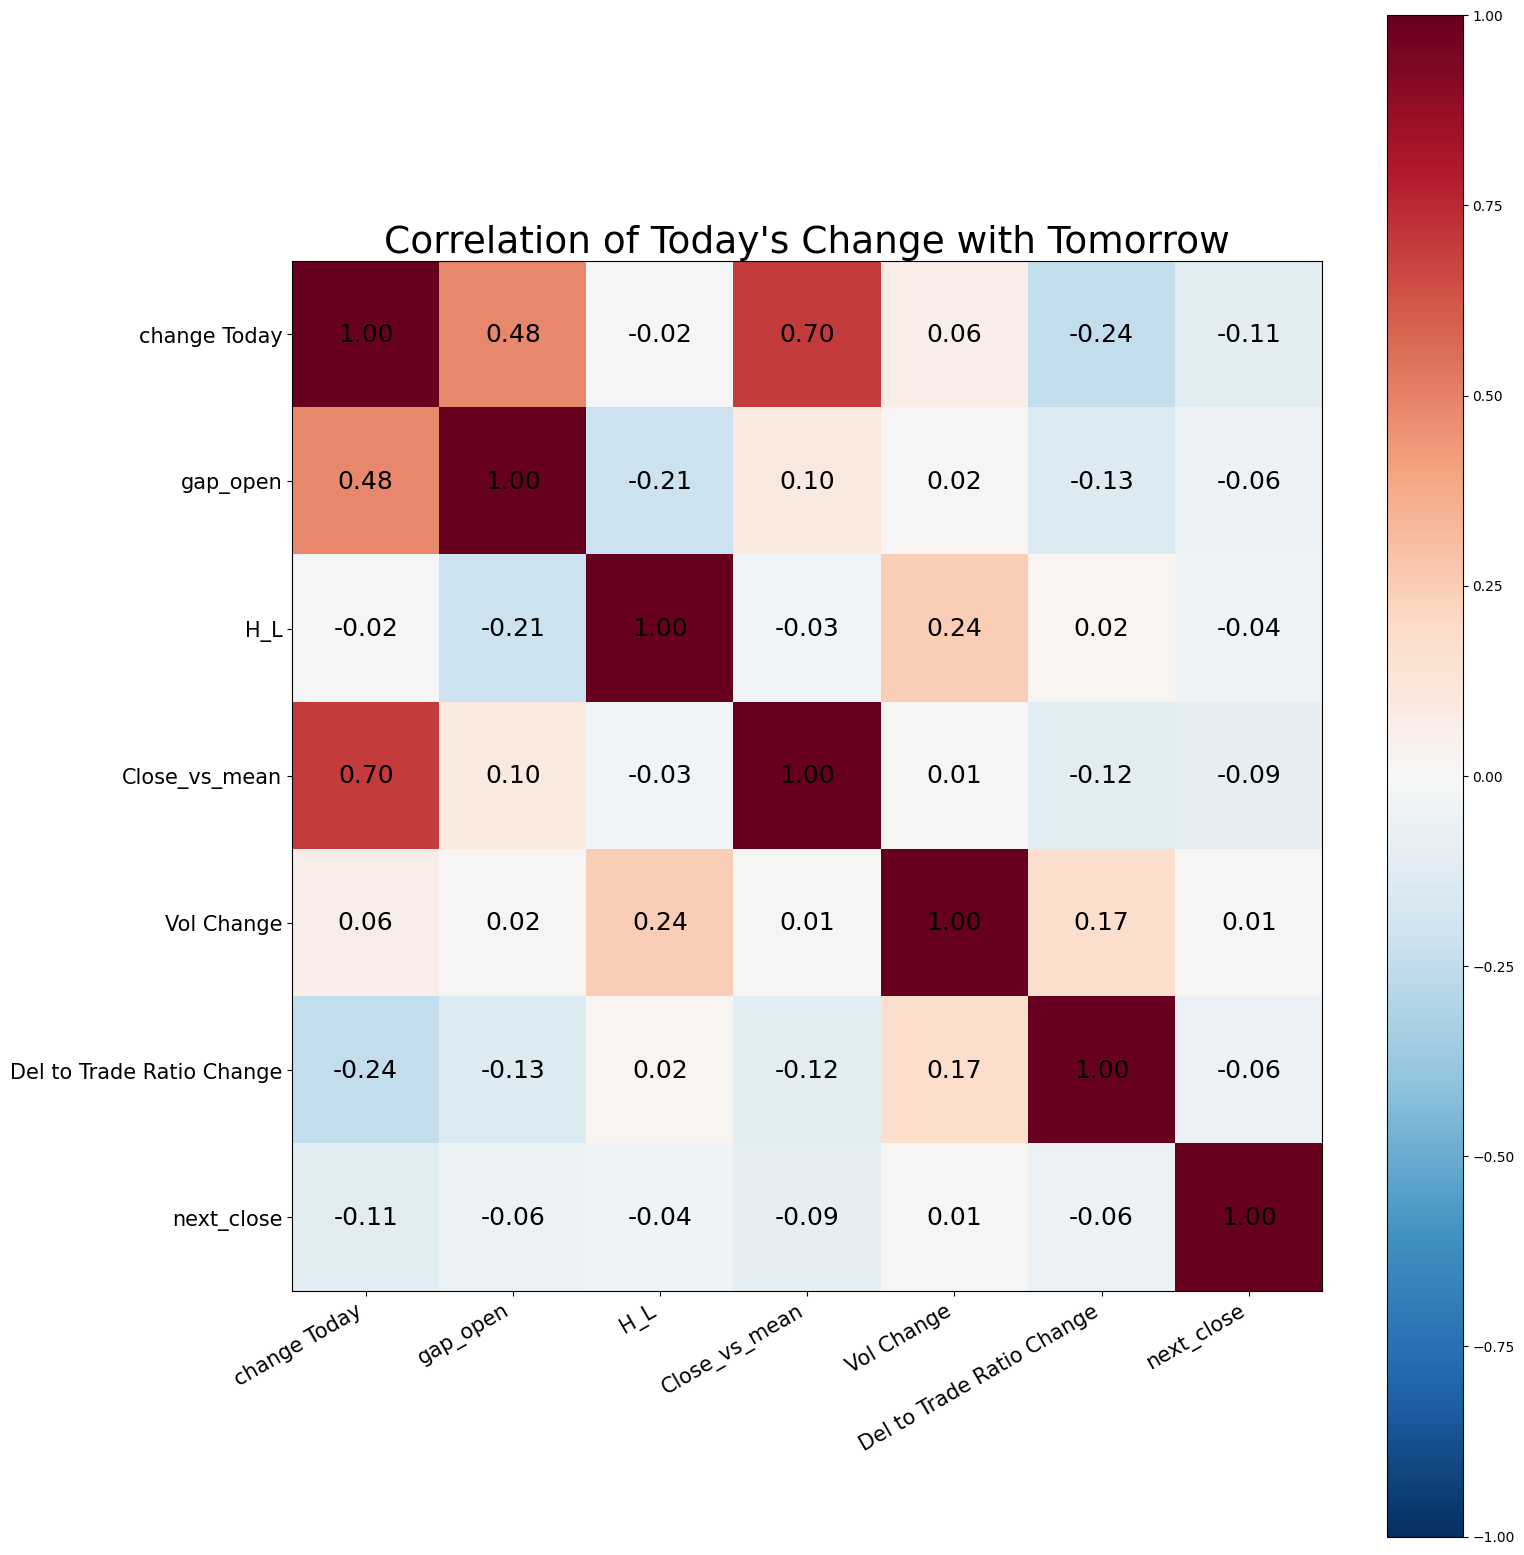

In [19]:
fig, ax = plt.subplots(figsize=(16,16))
im =  ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c.columns)))
ax.set_xticklabels(c.columns, rotation=30, ha="right",fontsize=15)
ax.set_yticks(range(len(c.columns)))
ax.set_yticklabels(c.columns, fontsize=15)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j,i,f"{c.iloc[i,j]:.2f}", ha="center", va="center", fontsize=18)
fig.colorbar(im,ax=ax)
ax.set_title("Correlation of Today's Change with Tomorrow", fontsize=27)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_signal_correlation.png", dpi=100, bbox_inches="tight")
plt.show()

In [20]:
next_corr = c["next_close"].drop("next_close")
strongest = next_corr.abs().idxmax()
print(f"{SYMBOL} - EDA summary")
print(f"Mean daily return       : {pct.mean():+.2%}")
print(f"Std of daily return     : {pct.std():.2%}")
print(f"Mean absolute move      : {pct.abs().mean():.2%}")
print(f"Largest absolute move   : {pct.abs().max():.2%} on {pct.abs().idxmax().date()}")
print(f"Naive mean abs error    : ₹{df['Close'].diff().abs().mean():.2f}")
print(f"Strongest next-day corr : {strongest} ({next_corr[strongest]:+.3f})")

TCS - EDA summary
Mean daily return       : +0.10%
Std of daily return     : 1.89%
Mean absolute move      : 1.34%
Largest absolute move   : 9.85% on 2020-03-20
Naive mean abs error    : ₹29.92
Strongest next-day corr : change Today (-0.110)


**Reading the EDA**

- The return statistics above give the scale of a typical daily move; the naive mean absolute error is the error any model has to improve on.
- Raw price columns usually correlate close to 1 with one another — a shared trend, not predictive information.
- The `next_close` row of the heatmap shows how strongly today's signals relate to tomorrow's return. Values near zero (|r| < 0.1) indicate limited short-term predictability; a negative sign suggests mean reversion, a positive sign momentum.

## 3. Feature Engineering

Each observation summarises the preceding `WINDOWS` trading days relative to the current close:

- Daily returns
- Open, high, low and average price relative to the current close
- Volume and number of trades relative to their window average (log scale)
- Delivery-to-traded ratio
- Window aggregates: cumulative return, volatility and distance from short- and full-window moving averages

The target variable is the **next-day return**. Modelling returns rather than price levels keeps the problem stationary; the test period trades above the training range, which price-level models — tree-based models in particular — cannot extrapolate to.

In [21]:
def data_window(df, window):
    close = df["Close"]
    cl_pre_ratio = close / df["Prev Close"] - 1
    vol_mean = df["Volume"].rolling(window).mean()
    trad_mean = df["Trades"].rolling(window).mean()
    feats = {}
    for k in range(window):
        feats[f"ratio_{k}"] = cl_pre_ratio.shift(k)
        for col in ["Open", "High", "Low", "Average"]:
            feats[f"{col}_{k}"] = df[col].shift(k) / close - 1
        if k > 0:
            feats[f"Close_{k}"] = close.shift(k) / close - 1
        feats[f"vol_{k}"] = np.log(df["Volume"].shift(k) / vol_mean)
        feats[f"Trade_{k}"] = np.log(df["Trades"].shift(k) / trad_mean)
        feats[f"Del_{k}"] = df["R_del_trd"].shift(k) / 100
    feats["long_close"] = close / df["Prev Close"].shift(window - 1) - 1
    feats["long_std"] = cl_pre_ratio.rolling(window).std()
    feats["window_mean"] = close / close.rolling(window).mean() - 1
    feats["half_window_mean"] = close / close.rolling(window//2).mean() - 1
    X = pd.DataFrame(feats, index=df.index)
    Y = pd.Series(df["Close"].shift(-1) / close - 1 , index=df.index)
    valid = X.notna().all(axis=1)
    return X[valid], Y[valid]

In [22]:
X_total, Y_total = data_window(df=df, window=WINDOWS)
X_future = X_total[Y_total.isna()]
X_future

,ratio_0,Open_0,High_0,Low_0,Average_0,vol_0,Trade_0,Del_0,ratio_1,Open_1,...,Low_9,Average_9,Close_9,vol_9,Trade_9,Del_9,long_close,long_std,window_mean,half_window_mean
Date,,,,,,,,,,,,,,,,,,,,,
2021-03-03,0.017546,-0.007878,0.001602,-0.020333,-0.007515,-0.149257,-0.093858,0.579,0.028093,-0.032395,...,-0.009186,-0.000379,-0.000572,0.027847,-0.131568,0.4874,-0.004556,0.021546,0.023275,0.027975


Rows with a known target form the modelling set; the final row is kept as `X_future` for the out-of-sample forecast.

In [23]:
X, Y = X_total[Y_total.notna()], Y_total[Y_total.notna()]
print("Shape of the Features:", X.shape)
print("Shape of the True:", Y.shape)

Shape of the Features: (486, 93)
Shape of the True: (486,)


**Sanity checks** — feature value ranges (no raw prices), and a look-ahead test: features for a mid-sample date must be identical when all later data is removed.

In [24]:
X.describe().T[["min","max"]].sort_values("max")

,min,max
Low_0,-0.166224,-0.001397
Average_0,-0.038604,0.037538
long_std,0.004360,0.056399
half_window_mean,-0.109500,0.070650
Open_0,-0.093160,0.075797
...,...,...
vol_4,-2.810025,1.229552
vol_0,-2.612344,1.239949
vol_3,-2.800487,1.242560
vol_2,-2.749222,1.254016


In [25]:
x_half = X.index[len(X) // 2]
X_mid, _ = data_window(df.loc[:x_half], WINDOWS)
if (X_mid.loc[x_half] == X.loc[x_half]).sum() == X.shape[1]:
    print("Verified")
else:
    raise AssertionError(f"The feature is not extracted Correctly")

Verified


The printed shape is samples × features, where the feature count is `9 × WINDOWS + 3` (nine per lag, minus the current close, plus four window aggregates). The last trading day has no target and is kept as `X_future` for the out-of-sample forecast. All features should be scale-free ratios — the min/max table should contain no values in the hundreds or thousands — and the look-ahead check must print *Verified*.

## 4. Train–Test Split

The most recent `TEST_PART` of observations is held out chronologically. Random shuffling is avoided, as it would allow training on observations that occur after the evaluation period.

In [26]:
def train_test(X,Y,fraction):
    idx_test = int(len(X) * fraction)

    X_train, X_test = X.iloc[:-idx_test], X.iloc[-idx_test:]
    Y_train, Y_test = Y.iloc[:-idx_test], Y.iloc[-idx_test:]

    print(f"Train: {X_train.index.min().date()} to {X_train.index.max().date()}")
    print(f"Test: {X_test.index.min().date()} to {X_test.index.max().date()}")
    return X_train, Y_train, X_test, Y_test

In [27]:
x_train, y_train, x_test, y_test = train_test(X=X, Y=Y, fraction=TEST_PART)

Train: 2019-03-18 to 2020-10-13
Test: 2020-10-14 to 2021-03-02


`train_test` prints both periods. Because the split is chronological, the training and test sets can fall in different market regimes (for example, a crash in training and a rally in testing); test results should be read with that in mind.

## 5. Baseline Models

Four rule-based forecasts establish the reference performance:

- **Naive** — next-day close equals the current close
- **Linear / Quadratic extrapolation** — polynomial fit through the last three closes
- **Window mean** — average of the last `WINDOWS` closes

All models are evaluated on the test set using RMSE, MAE, MAPE and direction error.

In [28]:
def baseline_model(df, dates, window):
    close = df["Close"]
    date_list = close.index.get_indexer(dates)
    naive, linear_3d, quard_3d, avg_10d = [], [], [], []
    for d in date_list:
        last_3d = close.iloc[d-2:d+1].values
        naive.append(close.iloc[d])
        linear_3d.append(np.polyval(np.polyfit([0,1,2],last_3d,1),3))
        quard_3d.append(np.polyval(np.polyfit([0,1,2], last_3d, 2), 3))
        avg_10d.append(close.iloc[d-window+1:d+1].mean())
    return pd.DataFrame({"Naive": naive, "Linear_3d": linear_3d,
                         "Qudratic_3d": quard_3d, "Window_mean": avg_10d},
                         index=dates)

In [29]:
baseline_p = baseline_model(df=df, dates=x_test.index, window=WINDOWS)
baseline_p

,Naive,Linear_3d,Qudratic_3d,Window_mean
Date,,,,
2020-10-14,2809.60,2801.650000,2779.15,2727.660
2020-10-15,2740.60,2706.300000,2619.55,2752.490
2020-10-16,2763.30,2724.866667,2877.70,2776.475
2020-10-19,2711.55,2709.433333,2585.35,2777.050
2020-10-20,2739.00,2713.650000,2845.65,2779.520
...,...,...,...,...
2021-02-24,2948.10,2951.900000,2862.15,3073.450
2021-02-25,2995.30,2989.633333,3121.80,3052.380
2021-02-26,2894.30,2892.100000,2645.10,3022.730


**Evaluation** — all forecasts are scored in ₹ against the actual next-day close. Direction error is the share of days with the wrong up/down call; it is undefined for the naive forecast, which never predicts a change. `section_summary` displays one section's models with `RMSE / Naive` and direction accuracy.

In [30]:
def evaluate(pred, true, today):
    err = true - pred
    rmse = np.sqrt((err ** 2).mean())
    mae = err.abs().mean()
    mape = (err.abs() / true).mean() * 100
    pred_dir = np.sign(pred - today)
    true_dir = np.sign(true - today)
    dir_err = np.nan if (pred == today).mean() else 1 - (pred_dir == true_dir).mean()
    return {"RMSE": rmse, "MAE": mae, "MAPE": mape, "Direction Error": dir_err}

In [31]:
results = pd.DataFrame({name: evaluate(baseline_p[name],
                                       df["Close"].shift(-1).loc[x_test.index],
                                       df["Close"].loc[x_test.index]) for name in baseline_p.columns}).T
results

,RMSE,MAE,MAPE,Direction Error
Naive,42.969087,34.756701,1.190772,NaN
Linear_3d,54.498778,44.608935,1.527001,0.556701
Qudratic_3d,106.469175,86.291753,2.974602,0.443299
Window_mean,82.200211,66.720928,2.254935,0.453608


In [32]:
def section_summary(names):
    s = results.loc[names, ["RMSE", "MAE", "Direction Error"]].copy()
    s["RMSE / Naive"] = s["RMSE"] / results.loc["Naive", "RMSE"]
    s["Direction Acc %"] = (1 - s["Direction Error"]) * 100
    return s.drop(columns="Direction Error").sort_values("RMSE").round(3)

Reusable plot: one panel per model, actual vs predicted next-day close on the test period.

In [33]:
def plot_predictions(pred_df, true, title, ncols=2):
    names = pred_df.columns
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.5 * nrows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, name in zip(axes.flat, names):
        rmse = np.sqrt(((true - pred_df[name]) ** 2).mean())
        ax.plot(true.index, true, color="black", lw=1.5, label="Actual")
        ax.plot(pred_df.index, pred_df[name], lw=1.2, alpha=0.8, label="Predicted")
        ax.set_title(f"{name}  (RMSE ₹{rmse:.2f})")
        ax.legend(loc="upper left", fontsize=8)
    for ax in axes.flat[len(names):]:      # hide unused panels
        ax.set_visible(False)
    fig.suptitle(title, fontsize=14)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

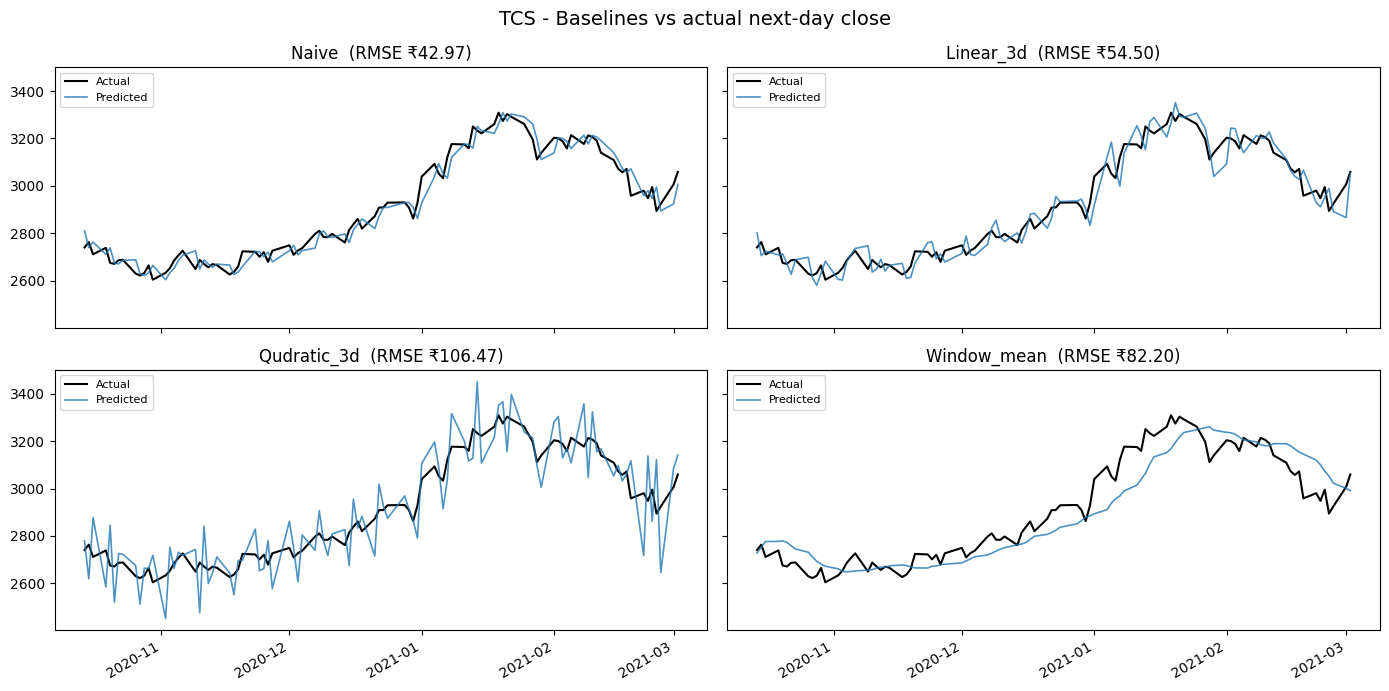

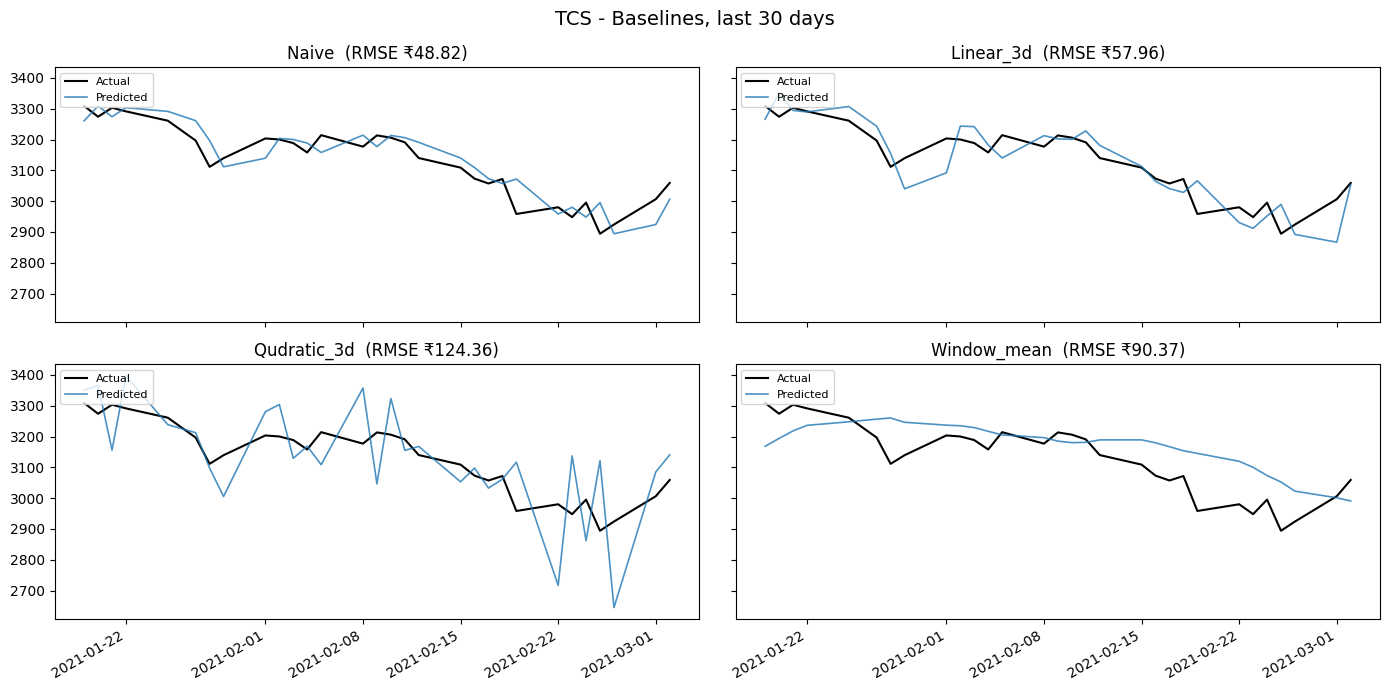

In [34]:
# x-axis = date the forecast was made (day t); values = forecast / actual close for day t+1
true_next = df["Close"].shift(-1).loc[x_test.index]
plot_predictions(baseline_p, true_next, f"{SYMBOL} - Baselines vs actual next-day close")
plot_predictions(baseline_p.iloc[-30:], true_next.iloc[-30:], f"{SYMBOL} - Baselines, last 30 days")

In [35]:
section_summary(list(baseline_p.columns))

,RMSE,MAE,RMSE / Naive,Direction Acc %
Naive,42.969,34.757,1.000,NaN
Linear_3d,54.499,44.609,1.268,44.330
Window_mean,82.200,66.721,1.913,54.639
Qudratic_3d,106.469,86.292,2.478,55.670


The naive forecast is usually hard to beat: extrapolation amplifies short-term noise and the moving average lags in trending markets. The naive RMSE is the benchmark for every subsequent model — `RMSE / Naive` below 1 means a model improves on it.

## 6. Linear Models

With `9 × WINDOWS + 3` features and only a few hundred training observations, ordinary least squares is prone to overfitting. Ridge (L2) and Lasso (L1) regularisation are therefore evaluated alongside it, with the regularisation strength `alpha` selected by time-series cross-validation on the training set.

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.base import clone

Shared helpers used by all ML models: return-to-price scoring, a scaling pipeline, and 5-fold `TimeSeriesSplit` cross-validation.

In [37]:
def model_pred(df, x_val, name, model, results, eval_fn):
    pred = model.predict(x_val)
    close = df["Close"].loc[x_val.index]
    true = df["Close"].shift(-1).loc[x_val.index]
    pred_price = close * (1 + pred)
    results.loc[name, ["RMSE", "MAE", "MAPE", "Direction Error"]] = pd.Series(eval_fn(pred_price, true, close))
    return results

In [38]:
scalar_pipline = lambda model: Pipeline([("scale", StandardScaler()), ("model", model)])
tscv = TimeSeriesSplit(n_splits=5)
cv = lambda model,X,Y,ts, : cross_val_score(estimator=model,X=X,y=Y,cv=ts,scoring="neg_root_mean_squared_error")

In [39]:
linear_model = {"Linear":[scalar_pipline(LinearRegression()), []],
                "Ridge":[scalar_pipline(Ridge()), [1, 10, 25, 50, 75, 100, 250, 500, 750, 1000, 2500, 5000, 10000, 25000, 50000, 75000, 100000]],
                "Lasso":[scalar_pipline(Lasso(max_iter=25000)), [100, 50, 25, 10, 1, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5]]}

In [40]:
test_preds = baseline_p[["Naive"]].copy()     # ₹ predictions on the test set, for plotting
linear_fitted = {}                            # selected model per type, for inspection

for i in ["Linear", "Ridge", "Lasso"]:
    model = linear_model[i][0]
    alpha = linear_model[i][1]
    if alpha:
        scores = {}
        for j in alpha:
            md = clone(model).set_params(model__alpha=j)
            scores[j] = -cv(model=md,X=x_train,Y=y_train,ts=tscv).mean()
        best_j = min(scores,key=scores.get)
        b = clone(model).set_params(model__alpha=best_j)
        print(f"{i}: best alpha = {best_j}, CV = {scores[best_j]}")
    else:
        b = model
        scores = -cv(model=b,X=x_train,Y=y_train,ts=tscv).mean()
        print(f"{i}: CV = {scores}")

    b.fit(x_train, y_train)
    linear_fitted[i] = b
    results = model_pred(df=df,x_val=x_test, name=i, model=b, results=results, eval_fn=evaluate)
    test_preds[i] = df["Close"].loc[x_test.index] * (1 + b.predict(x_test))

results

Linear: CV = 0.03654799477816284
Ridge: best alpha = 100000, CV = 0.020138707113025494


c:\Users\smart\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.506e-05, tolerance: 1.412e-06
  model = cd_fast.enet_coordinate_descent(


Lasso: best alpha = 100, CV = 0.020138743381753553


,RMSE,MAE,MAPE,Direction Error
Naive,42.969087,34.756701,1.190772,NaN
Linear_3d,54.498778,44.608935,1.527001,0.556701
Qudratic_3d,106.469175,86.291753,2.974602,0.443299
Window_mean,82.200211,66.720928,2.254935,0.453608
Linear,53.759394,42.637071,1.456979,0.536082
Ridge,42.922445,34.713324,1.188606,0.474227
Lasso,42.916006,34.779008,1.190817,0.474227


Inspection of the selected Lasso model: number of retained coefficients and the resulting forecast.

In [41]:
lasso = linear_fitted["Lasso"]
print("Selected alpha:", lasso.named_steps["model"].alpha)
print("Non-zero coefficients:", (lasso.named_steps["model"].coef_ != 0).sum(), "of", x_train.shape[1])
print("Intercept (daily drift):", lasso.named_steps["model"].intercept_)
print("Unique predictions:", len(np.unique(lasso.predict(x_test).round(6))))

Selected alpha: 100
Non-zero coefficients: 0 of 93
Intercept (daily drift): 0.001044517419936087
Unique predictions: 1


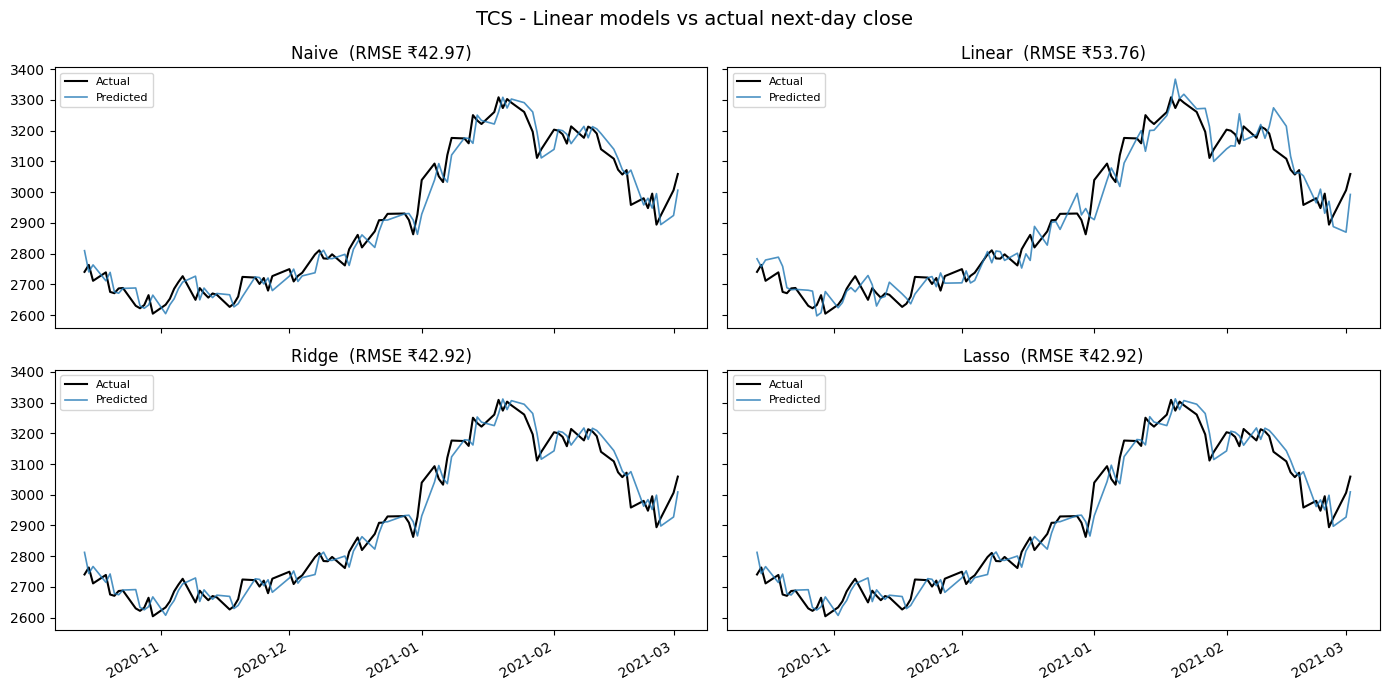

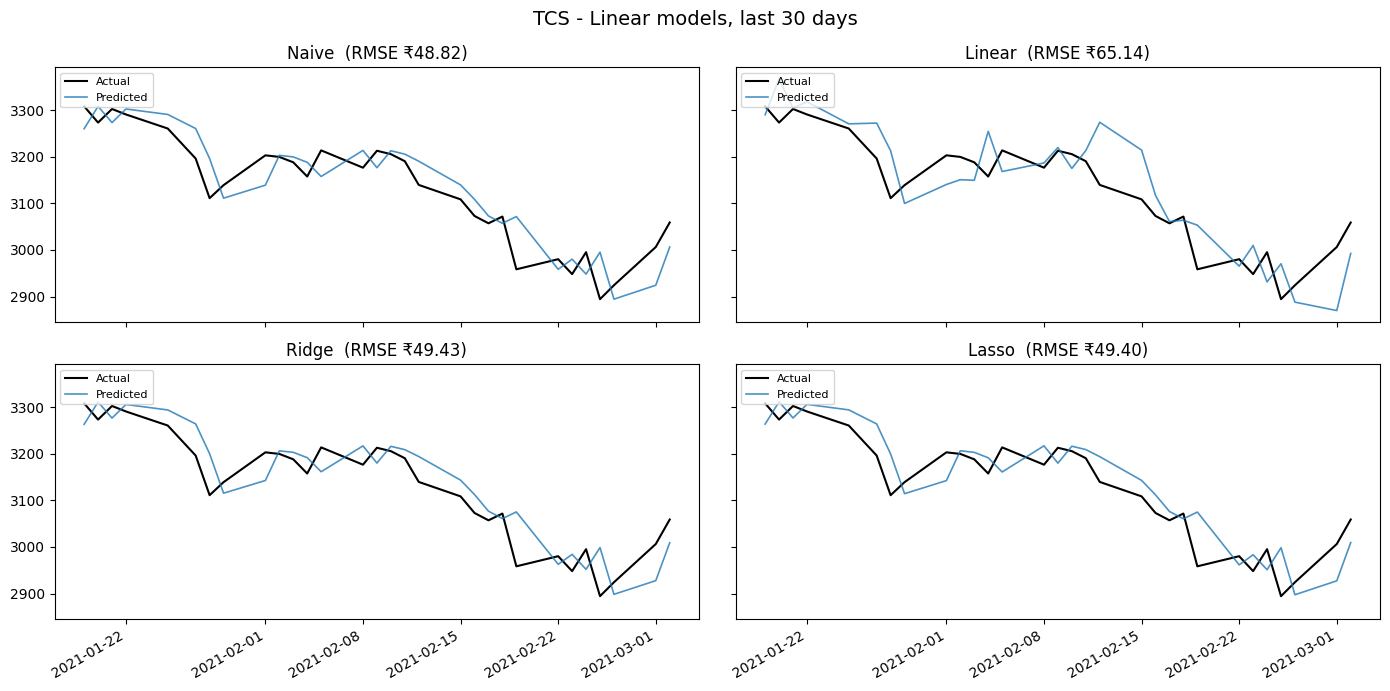

In [42]:
linear_cols = ["Naive", "Linear", "Ridge", "Lasso"]
plot_predictions(test_preds[linear_cols], true_next, f"{SYMBOL} - Linear models vs actual next-day close")
plot_predictions(test_preds[linear_cols].iloc[-30:], true_next.iloc[-30:], f"{SYMBOL} - Linear models, last 30 days")

In [43]:
section_summary(["Naive", "Linear", "Ridge", "Lasso"])

,RMSE,MAE,RMSE / Naive,Direction Acc %
Lasso,42.916,34.779,0.999,52.577
Ridge,42.922,34.713,0.999,52.577
Naive,42.969,34.757,1.000,NaN
Linear,53.759,42.637,1.251,46.392


**Interpreting the linear models**

- A large gap between Linear Regression and naive indicates overfitting.
- If the selected `alpha` is the largest value in its grid, cross-validation prefers maximum shrinkage — a sign that the features add no reliable linear signal.
- The Lasso inspection shows how many coefficients survive. Zero retained coefficients means the model predicts a constant equal to the average training return, i.e. a "naive plus drift" forecast.

## 7. K-Nearest Neighbours

KNN tests for non-linear structure by forecasting from the outcomes of the most similar historical windows. The number of neighbours and the weighting scheme are tuned with `GridSearchCV` on the same time-series folds.

Grid-search helper reused for all remaining models: tunes on the training folds, then scores the refitted best estimator on the test set.

In [44]:
from sklearn.model_selection import GridSearchCV

In [45]:
def grid_search_score(name, model, grid, ts, x_train, y_train, df, x_test, results):
    gs = GridSearchCV(estimator=model, param_grid=grid, cv=ts,
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(x_train, y_train)
    print(f"{name}: best {gs.best_params_} CV RMSE {-gs.best_score_:.6f}")
    results = model_pred(df, x_test, name, gs.best_estimator_, results, evaluate)
    return gs

In [46]:
from sklearn.neighbors import KNeighborsRegressor

In [47]:
knn_grid = {"model__n_neighbors": [5, 10, 20, 30, 50, 75, 100],
            "model__weights": ["uniform", "distance"]}
knn_gs = grid_search_score(name="KNN", model=scalar_pipline(KNeighborsRegressor()), grid=knn_grid,
                           ts=tscv, x_train=x_train, y_train=y_train, df=df,
                           x_test=x_test, results=results)
results

c:\Users\smart\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [-0.02074809 -0.02075329 -0.02050762 -0.02050295 -0.02044303 -0.02043252
 -0.02039758 -0.02039138 -0.02032039 -0.02031862         nan         nan
         nan         nan]
  warnings.warn(


KNN: best {'model__n_neighbors': 50, 'model__weights': 'distance'} CV RMSE 0.020319


,RMSE,MAE,MAPE,Direction Error
Naive,42.969087,34.756701,1.190772,NaN
Linear_3d,54.498778,44.608935,1.527001,0.556701
Qudratic_3d,106.469175,86.291753,2.974602,0.443299
Window_mean,82.200211,66.720928,2.254935,0.453608
Linear,53.759394,42.637071,1.456979,0.536082
Ridge,42.922445,34.713324,1.188606,0.474227
Lasso,42.916006,34.779008,1.190817,0.474227
KNN,42.680244,34.195977,1.172519,0.443299


Cross-validated error as a function of k.

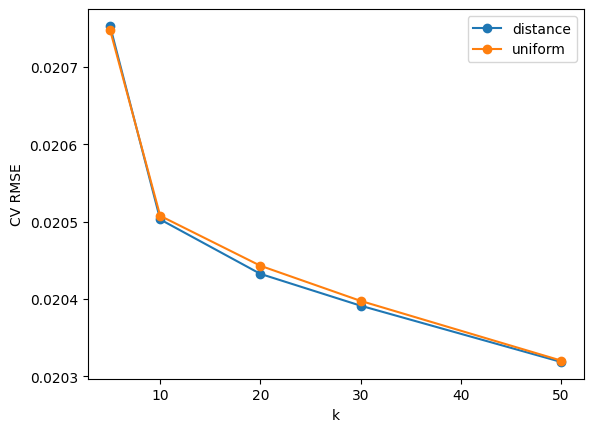

In [48]:
cvr = pd.DataFrame(knn_gs.cv_results_)
fig, ax = plt.subplots()
for w, grp in cvr.groupby("param_model__weights"):
    ax.plot(grp["param_model__n_neighbors"], -grp["mean_test_score"], marker="o", label=w)
ax.set_xlabel("k")
ax.set_ylabel("CV RMSE")
ax.legend()
plt.show()

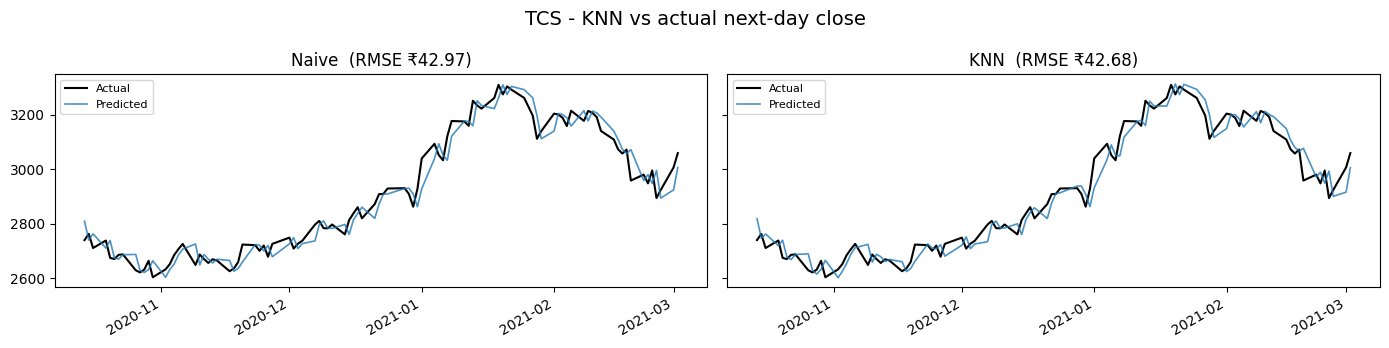

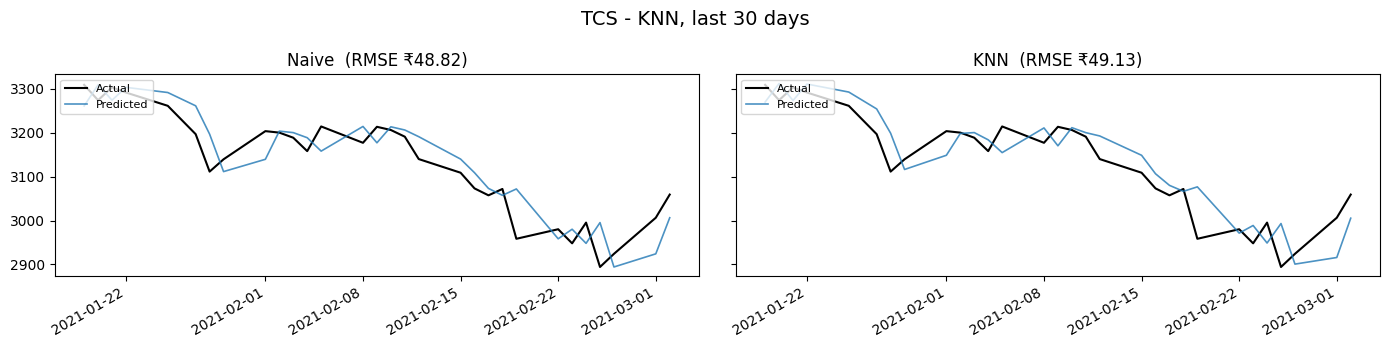

In [49]:
test_preds["KNN"] = df["Close"].loc[x_test.index] * (1 + knn_gs.best_estimator_.predict(x_test))
plot_predictions(test_preds[["Naive", "KNN"]], true_next, f"{SYMBOL} - KNN vs actual next-day close")
plot_predictions(test_preds[["Naive", "KNN"]].iloc[-30:], true_next.iloc[-30:], f"{SYMBOL} - KNN, last 30 days")

In [50]:
section_summary(["Naive", "KNN"])

,RMSE,MAE,RMSE / Naive,Direction Acc %
KNN,42.680,34.196,0.993,55.67
Naive,42.969,34.757,1.000,NaN


**Interpreting KNN**

- A large selected k averages many comparable periods and keeps forecasts close to the mean return; a small k relies on a few very similar windows and is more prone to noise.
- An improvement here that the linear models did not achieve points to non-linear structure in the features.
- Values of k larger than the smallest cross-validation training fold return NaN and are skipped automatically.

## 8. Support Vector Regression

SVR ignores errors smaller than `epsilon`, which must be calibrated to the scale of daily returns. The default configuration is examined first, followed by a grid search over `C`, `epsilon` and `gamma` (RBF kernel). The analysis assesses whether the tuned model captures signal or converges to a near-constant forecast, as observed with the regularised linear models.

In [51]:
from sklearn.svm import SVR

# The default-epsilon trap: epsilon=0.1 means "ignore errors under 10%" -> every daily return is inside the tube
svr_default = scalar_pipline(SVR()).fit(x_train, y_train)
print("Default SVR support vectors:", len(svr_default.named_steps["model"].support_), "of", len(x_train))
print("Default SVR unique predictions:", np.unique(svr_default.predict(x_test).round(6)))

Default SVR support vectors: 0 of 389
Default SVR unique predictions: [0.002174]


In [52]:
svr_grid = {"model__C": [0.0001, 0.001, 0.01, 0.1, 1],
            "model__epsilon": [0.001, 0.005, 0.01, 0.02],
            "model__gamma": ["scale", 0.001, 0.0001]}
svr_gs = grid_search_score(name="SVR", model=scalar_pipline(SVR(kernel="rbf")), grid=svr_grid,
                           ts=tscv, x_train=x_train, y_train=y_train, df=df,
                           x_test=x_test, results=results)
results

SVR: best {'model__C': 0.0001, 'model__epsilon': 0.001, 'model__gamma': 'scale'} CV RMSE 0.020103


,RMSE,MAE,MAPE,Direction Error
Naive,42.969087,34.756701,1.190772,NaN
Linear_3d,54.498778,44.608935,1.527001,0.556701
Qudratic_3d,106.469175,86.291753,2.974602,0.443299
Window_mean,82.200211,66.720928,2.254935,0.453608
Linear,53.759394,42.637071,1.456979,0.536082
Ridge,42.922445,34.713324,1.188606,0.474227
Lasso,42.916006,34.779008,1.190817,0.474227
KNN,42.680244,34.195977,1.172519,0.443299
SVR,42.896517,34.666806,1.187535,0.484536


Support vectors: 350 of 389
Predicted return: mean 0.00036, std 0.00019, unique 96


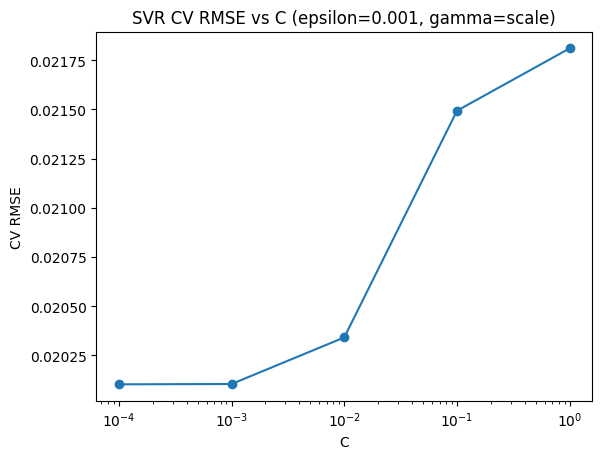

In [53]:
# Inspect the tuned SVR: how many points shape it, and do its predictions actually vary?
svr_best = svr_gs.best_estimator_
svr_ret = svr_best.predict(x_test)
print("Support vectors:", len(svr_best.named_steps["model"].support_), "of", len(x_train))
print(f"Predicted return: mean {svr_ret.mean():.5f}, std {svr_ret.std():.5f}, unique {len(np.unique(svr_ret.round(7)))}")

# CV RMSE vs C (best epsilon/gamma held fixed)
cvr = pd.DataFrame(svr_gs.cv_results_)
best_eps = svr_gs.best_params_["model__epsilon"]
best_gamma = svr_gs.best_params_["model__gamma"]
sub = cvr[(cvr["param_model__epsilon"] == best_eps) & (cvr["param_model__gamma"] == best_gamma)]
fig, ax = plt.subplots()
ax.plot(sub["param_model__C"].astype(float), -sub["mean_test_score"], marker="o")
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("CV RMSE")
ax.set_title(f"SVR CV RMSE vs C (epsilon={best_eps}, gamma={best_gamma})")
plt.show()

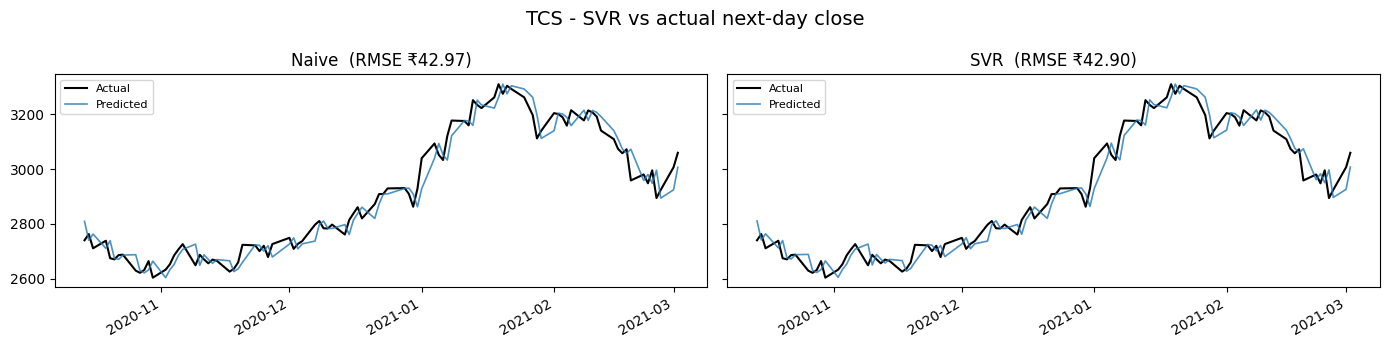

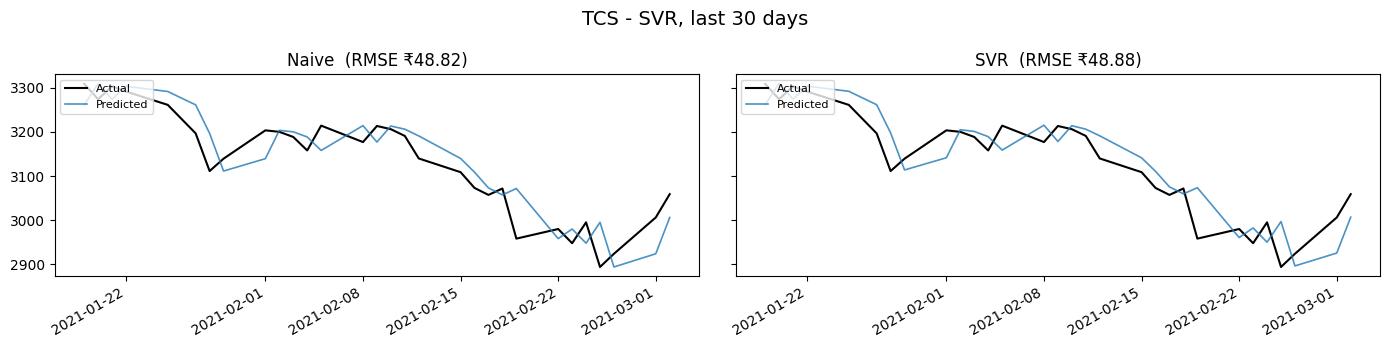

In [54]:
test_preds["SVR"] = df["Close"].loc[x_test.index] * (1 + svr_ret)
plot_predictions(test_preds[["Naive", "SVR"]], true_next, f"{SYMBOL} - SVR vs actual next-day close")
plot_predictions(test_preds[["Naive", "SVR"]].iloc[-30:], true_next.iloc[-30:], f"{SYMBOL} - SVR, last 30 days")

In [55]:
section_summary(["Naive", "KNN", "SVR"])

,RMSE,MAE,RMSE / Naive,Direction Acc %
KNN,42.680,34.196,0.993,55.670
SVR,42.897,34.667,0.998,51.546
Naive,42.969,34.757,1.000,NaN


**Interpreting SVR**

- The default configuration usually yields no support vectors and a constant forecast, because daily returns are smaller than `epsilon = 0.1`.
- For the tuned model, check whether the selected `C` lies at the edge of the grid and how much the predicted returns vary. A very small spread means the model has collapsed to a near-constant (drift) forecast.
- Compare with KNN to see whether a smooth kernel model adds anything over a neighbour-based one.

## 9. Tree-Based Models

Tree models can capture interactions and threshold effects (e.g. a large decline on high volume) that linear and distance-based models cannot express. Five models of increasing complexity are evaluated — a single Decision Tree, two bagging ensembles (Random Forest, Extra Trees) and two boosting ensembles (Gradient Boosting, XGBoost). Each is tuned with `GridSearchCV` on the same time-series folds. Feature scaling is not required.

In [56]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

In [57]:
bagging_grid = {"max_depth": [3, 6, None], "min_samples_leaf": [5, 20], "max_features": [0.3, 1.0]}

tree_models = {
    "Decision Tree": (DecisionTreeRegressor(random_state=42),
                      {"max_depth": [2, 3, 5], "min_samples_leaf": [10, 30]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=42), bagging_grid),
    "Extra Trees": (ExtraTreesRegressor(n_estimators=300, random_state=42), bagging_grid),
    "Gradient Boosting": (GradientBoostingRegressor(subsample=0.8, random_state=42),
                          {"n_estimators": [100, 300], "learning_rate": [0.01, 0.05], "max_depth": [2, 3]}),
    "XGBoost": (XGBRegressor(subsample=0.8, colsample_bytree=0.5, random_state=42, n_jobs=1),
                {"n_estimators": [100, 300], "learning_rate": [0.01, 0.05], "max_depth": [2, 3],
                 "reg_lambda": [1, 10]}),
}

tree_gs = {}
for name, (model, grid) in tree_models.items():
    tree_gs[name] = grid_search_score(name=name, model=model, grid=grid,
                                      ts=tscv, x_train=x_train, y_train=y_train, df=df,
                                      x_test=x_test, results=results)
    test_preds[name] = df["Close"].loc[x_test.index] * (1 + tree_gs[name].best_estimator_.predict(x_test))

Decision Tree: best {'max_depth': 2, 'min_samples_leaf': 30} CV RMSE 0.021534
Random Forest: best {'max_depth': 3, 'max_features': 0.3, 'min_samples_leaf': 20} CV RMSE 0.020268
Extra Trees: best {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 20} CV RMSE 0.020177
Gradient Boosting: best {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100} CV RMSE 0.020394
XGBoost: best {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 1} CV RMSE 0.020239


Feature importance for the tree model with the best CV score.

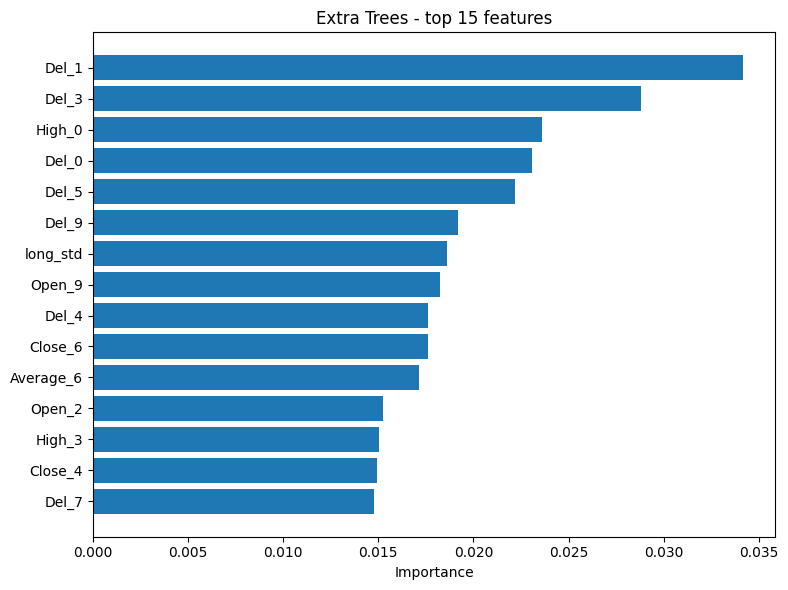

In [58]:
# Feature importance of the tree model with the best CV score (selected on training data only)
best_tree = max(tree_gs, key=lambda n: tree_gs[n].best_score_)
imp = pd.Series(tree_gs[best_tree].best_estimator_.feature_importances_, index=x_train.columns).nlargest(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index[::-1], imp.values[::-1])
ax.set_xlabel("Importance")
ax.set_title(f"{best_tree} - top 15 features")
plt.tight_layout()
fig.savefig(FIG_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

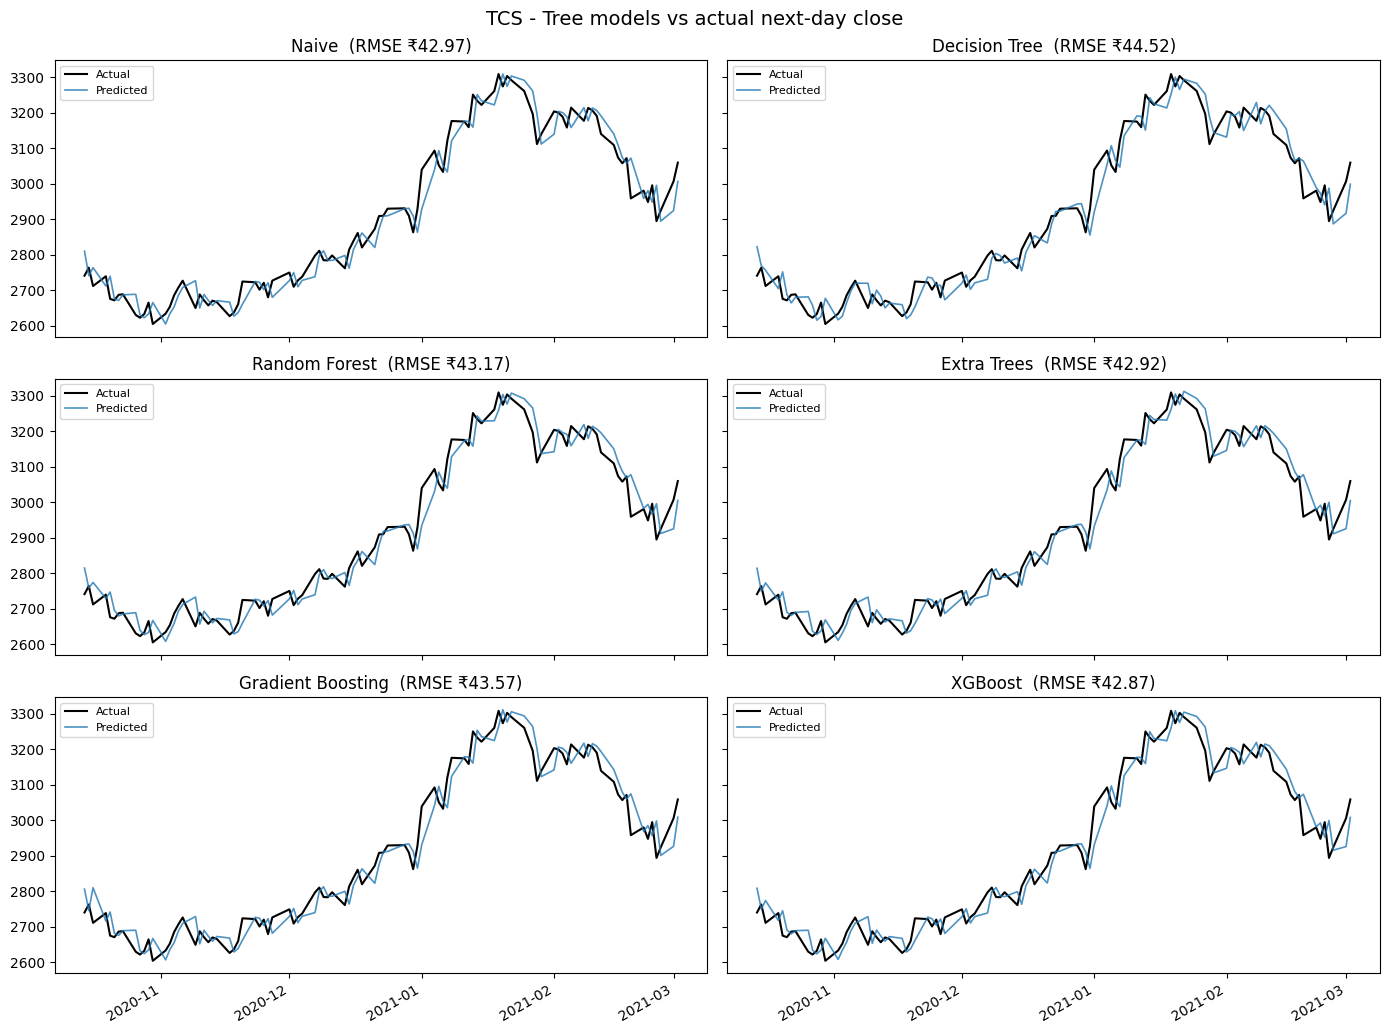

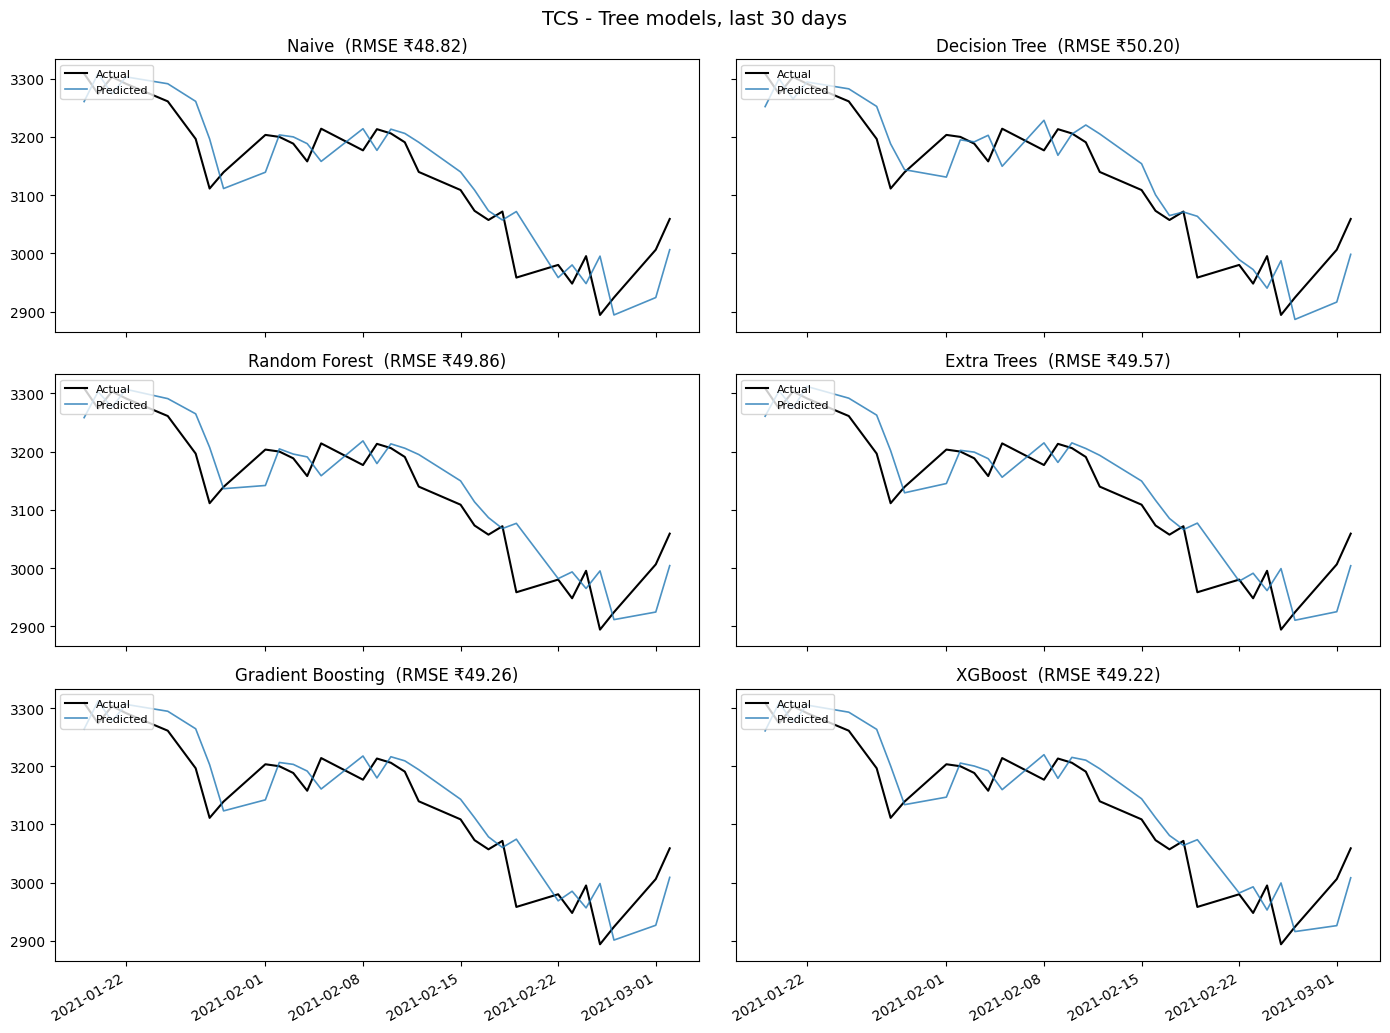

In [59]:
tree_cols = ["Naive"] + list(tree_models)
plot_predictions(test_preds[tree_cols], true_next, f"{SYMBOL} - Tree models vs actual next-day close")
plot_predictions(test_preds[tree_cols].iloc[-30:], true_next.iloc[-30:], f"{SYMBOL} - Tree models, last 30 days")

In [60]:
section_summary(["Naive"] + list(tree_models))

,RMSE,MAE,RMSE / Naive,Direction Acc %
XGBoost,42.871,34.262,0.998,55.670
Extra Trees,42.918,34.018,0.999,54.639
Naive,42.969,34.757,1.000,NaN
Random Forest,43.167,34.129,1.005,52.577
Gradient Boosting,43.574,34.956,1.014,53.608
Decision Tree,44.518,36.234,1.036,45.361


**Interpreting the tree models**

- The printed best parameters show how constrained each model is. Shallow depth, large leaves, a low learning rate and few boosting rounds mean cross-validation prefers predictions close to the mean.
- A single Decision Tree is usually the weakest; bagging and boosting reduce its variance.
- In the feature-importance chart, a few dominant features would suggest a genuine signal, while thinly spread importances suggest the model is mostly fitting noise. Note which feature groups (returns, price shape, volume, delivery ratio) rank highest.

## 10. Model Comparison

All models ranked by test RMSE. `RMSE / Naive` below 1 indicates an improvement over the naive benchmark.

In [61]:
summary = results.copy()
summary["RMSE / Naive"] = summary["RMSE"] / summary.loc["Naive", "RMSE"]
summary["Direction Acc %"] = (1 - summary["Direction Error"]) * 100
summary = summary.sort_values("RMSE")

summary.style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "MAPE": "{:.3f}",
                      "Direction Error": "{:.3f}", "RMSE / Naive": "{:.3f}",
                      "Direction Acc %": "{:.1f}"}) \
       .background_gradient(subset=["RMSE / Naive"], cmap="RdYlGn_r")

,RMSE,MAE,MAPE,Direction Error,RMSE / Naive,Direction Acc %
KNN,42.68,34.20,1.173,0.443,0.993,55.7
XGBoost,42.87,34.26,1.174,0.443,0.998,55.7
SVR,42.90,34.67,1.188,0.485,0.998,51.5
Lasso,42.92,34.78,1.191,0.474,0.999,52.6
Extra Trees,42.92,34.02,1.167,0.454,0.999,54.6
Ridge,42.92,34.71,1.189,0.474,0.999,52.6
Naive,42.97,34.76,1.191,nan,1.000,nan
Random Forest,43.17,34.13,1.171,0.474,1.005,52.6
Gradient Boosting,43.57,34.96,1.198,0.464,1.014,53.6
Decision Tree,44.52,36.23,1.244,0.546,1.036,45.4


In [62]:
ml = summary.drop(index=baseline_p.columns)
best = ml.index[0]
print(f"{SYMBOL} | window = {WINDOWS} days | test = {len(x_test)} days ({x_test.index.min().date()} to {x_test.index.max().date()})")
print(f"Naive RMSE  : ₹{summary.loc['Naive', 'RMSE']:.2f}")
print(f"Best model  : {best} - RMSE ₹{ml.loc[best, 'RMSE']:.2f} "
      f"({(ml.loc[best, 'RMSE / Naive'] - 1):+.1%} vs naive), direction accuracy {ml.loc[best, 'Direction Acc %']:.1f}%")
print("Beat naive  :", ", ".join(ml.index[ml["RMSE / Naive"] < 1]) or "none")

TCS | window = 10 days | test = 97 days (2020-10-14 to 2021-03-02)
Naive RMSE  : ₹42.97
Best model  : KNN - RMSE ₹42.68 (-0.7% vs naive), direction accuracy 55.7%
Beat naive  : KNN, XGBoost, SVR, Lasso, Extra Trees, Ridge


**Interpreting the comparison**

- Margins of only a few tenths of a percent over naive on a short test window are inconclusive; they can change with the test period or window length.
- Models that converge to the average-drift forecast will cluster just around `RMSE / Naive ≈ 1`.
- Stronger evidence of predictability is a consistent improvement across several symbols, `WINDOWS` values and test splits, together with direction accuracy clearly above the share of up days in the test period.